<a href="https://colab.research.google.com/github/kalindaunesa/Text-Processing-Exercise-7/blob/main/Text_Clustering_Exercise_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Unsupervised: KMeans

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

import pandas as pd
df = pd.read_csv('candy_crush_preprocessed.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

In [3]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud

In [4]:
k = range(1,7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10) # jumlah cluster akan di looping
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print(list(k))
print(inertia)

[1, 2, 3, 4, 5, 6]
[483.69507157761865, 481.6832214981385, 472.790206573827, 462.4701900933609, 460.2600918861154, 453.5618929639819]


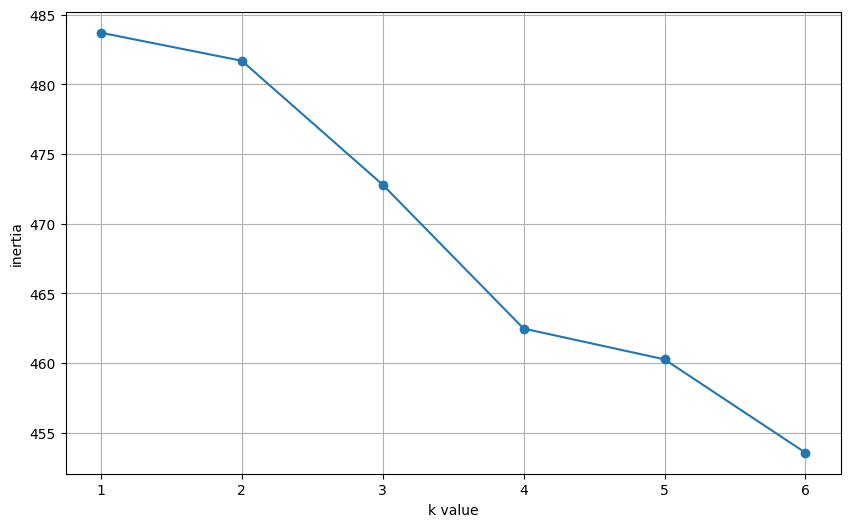

In [5]:
plt.figure(figsize=(10,6))
plt.plot(k, inertia, marker='o')
plt.xlabel('k value')
plt.ylabel('inertia')
plt.grid()
plt.show()

In [6]:
n_clusters = 3

In [7]:
kM = KMeans(n_clusters=n_clusters, random_state=10).fit(df_FE)
kM


KMeans(n_clusters=3, random_state=10)

In [8]:
df['Kmeans_label'] = kM.labels_
df.head()

,reviewId,score,text,prepro,Kmeans_label
0,147def9f-8981-48fc-9443-ed1dac3dc31f,5,The experience is good but it would be better ...,experience good would better offline online 👍,0
1,cb5f95ab-72c8-40a0-9c2c-a5c42d9bf849,5,it is best game for playing. it has alot of ch...,best game playing alot challenges win many goo...,1
2,89846120-bd9f-4d3b-a280-adc90c462474,3,"ads keep taking you out of app, losing your pr...",ads keep taking app losing progress,2
3,bb03bf32-38ce-4ad7-b48c-85bd2b979700,4,Recent update there is no any life saving ads ...,recent update life saving ads game 😔😔,2
4,e0f6c9c5-7a30-43ec-9d91-f4162e9132f4,5,"Brilliant game, love this, so addictive, won't...",brilliant game love addictive ever stop playing,1


**Silhouette Score**

In [9]:
from sklearn import metrics
labels = kM.labels_
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.008814731004965179)

**Word Cloud**

Kmeans for cluster 0


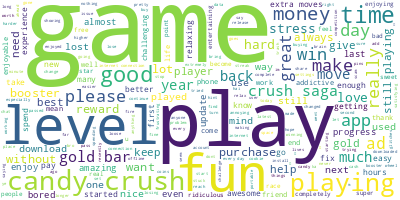

In [10]:
c = 0
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 1


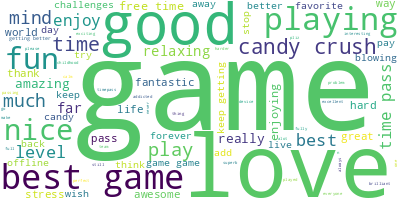

In [11]:
c = 1
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

Kmeans for cluster 2


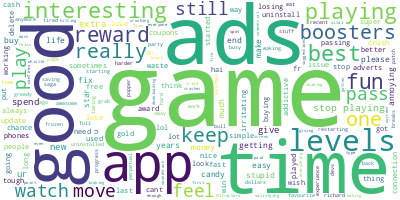

In [12]:
c = 2
print('Kmeans for cluster '+str(c))
df_c = df[df['Kmeans_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

## Unsupervised: Hierarchical

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage

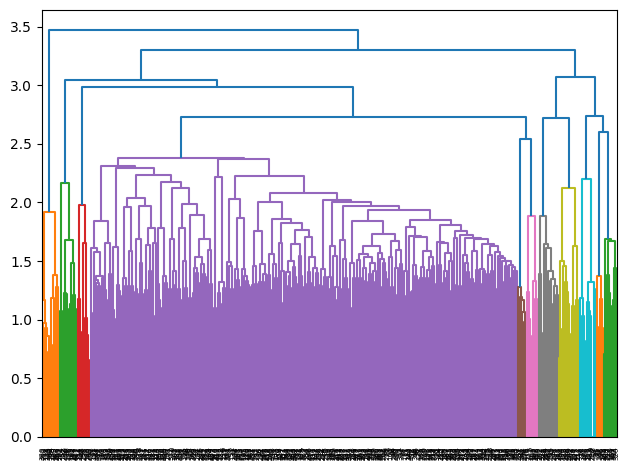

In [14]:
linkage_data = linkage(df_FE, method = 'ward', metric = 'euclidean')
dendrogram(linkage_data)
plt.tight_layout()
plt.show()

In [15]:
from sklearn.cluster import AgglomerativeClustering
hierarchical_cluster = AgglomerativeClustering(n_clusters = n_clusters, linkage = 'ward')
labels = hierarchical_cluster.fit(df_FE)

pred_agc = pd.Series(hierarchical_cluster.labels_)
df['Ward_label'] = pred_agc

In [16]:
df.head()

,reviewId,score,text,prepro,Kmeans_label,Ward_label
0,147def9f-8981-48fc-9443-ed1dac3dc31f,5,The experience is good but it would be better ...,experience good would better offline online 👍,0,2
1,cb5f95ab-72c8-40a0-9c2c-a5c42d9bf849,5,it is best game for playing. it has alot of ch...,best game playing alot challenges win many goo...,1,2
2,89846120-bd9f-4d3b-a280-adc90c462474,3,"ads keep taking you out of app, losing your pr...",ads keep taking app losing progress,2,2
3,bb03bf32-38ce-4ad7-b48c-85bd2b979700,4,Recent update there is no any life saving ads ...,recent update life saving ads game 😔😔,2,2
4,e0f6c9c5-7a30-43ec-9d91-f4162e9132f4,5,"Brilliant game, love this, so addictive, won't...",brilliant game love addictive ever stop playing,1,2


**Silhouette Score**

In [17]:
from sklearn import metrics
labels = pred_agc
metrics.silhouette_score(df_FE, labels, metric='euclidean')

np.float64(0.0022348358578064245)

**Word Cloud**

Hierarchical for cluster 0


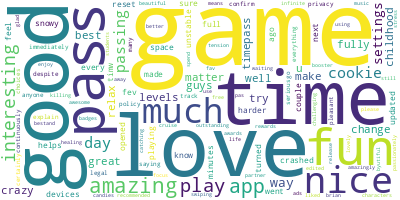

In [18]:
c = 0
print('Hierarchical for cluster '+str(c))
df_c = df[df['Ward_label'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string)
wordcloud.to_image()

## Supervised: Sentiment Analysis

Turning Score into Sentiment (since our csv doesn't have Sentiment column)

In [24]:
def to_sentiment(s):
    if s >= 4: return 'positive'
    if s == 3: return 'neutral'
    return 'negative'

df['Sentiment'] = df['score'].apply(to_sentiment)

Sentiment positive


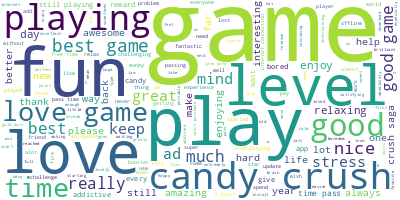

In [20]:
from wordcloud import WordCloud
c = 'positive'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

Sentiment negative


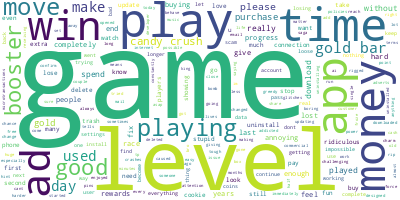

In [21]:
from wordcloud import WordCloud
c = 'negative'
print('Sentiment '+str(c))
df_c = df[df['Sentiment'] == c]
long_string = ','.join(list(df_c['prepro'].values))
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3)
wordcloud.generate(long_string); wordcloud.to_image()

In [22]:
import pandas as pd
df = pd.read_csv('candy_crush_preprocessed.csv')
df = df.dropna().reset_index().drop(columns=['index'])
df_pre = df['prepro']

# Mengubah teks menjadi matriks TF-IDF
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer()
vecs = vectorizer.fit_transform(df_pre)
vecs

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4178 stored elements and shape (500, 1408)>

In [25]:
# Classify
X = vecs # FE result
y = df['Sentiment']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

model = RandomForestClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[  2   0  23]
 [  0   0  11]
 [  1   0 113]]
              precision    recall  f1-score   support

    negative       0.67      0.08      0.14        25
     neutral       0.00      0.00      0.00        11
    positive       0.77      0.99      0.87       114

    accuracy                           0.77       150
   macro avg       0.48      0.36      0.34       150
weighted avg       0.70      0.77      0.68       150



In [26]:
testing = "The experience is good but it would be better if you do it both offline and online"
testing = vectorizer.transform([testing])
testing = model.predict(testing)
print(testing)

['positive']
